**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Clase 19 - Simulación de datos y muestreo**

*Cuánto podemos confiar en una muestra, y cómo simular para averiguarlo*

---

## Complemento

Este notebook se recorre **en paralelo** con la presentación **`Simulacion_y_muestreo.pdf`** (carpeta `PPT's/` del repo): en la PPT está el concepto y la intuición, acá la ejecución.

## ¿Qué vamos a hacer en esta clase?

En la clase 06 aprendimos **cómo** sacar una muestra con pandas (aleatoria, porcentual, estratificada, por conglomerados).
Hoy nos hacemos la pregunta que viene después: **¿cuánto podemos confiar en lo que dice una muestra?**

Para responderla vamos a **simular**: en vez de esperar datos reales, fabricamos una población donde **conocemos la verdad** y vemos cuánto se equivoca cada muestra.

| Parte | Tema | Herramienta |
|---|---|---|
| **A** | Números aleatorios y semilla | `np.random.default_rng` |
| **B** | Armar una población para simular | distribuciones, `pandas` |
| **C** | Una muestra y su error | muestra aleatoria simple |
| **D** | Mil muestras: la distribución muestral | ley de los grandes números, teorema central del límite |
| **E** | ¿Qué tamaño de muestra necesito? | error estándar, margen de error |
| **F** | Cómo se muestrea importa | aleatorio, estratificado, sistemático, por conveniencia |
| **G** | Simulación de Monte Carlo | simular un proyecto de inversión |
| **H** | Bootstrap | remuestrear una sola muestra |

> **La idea que atraviesa la clase:** una muestra bien tomada se equivoca **poco y sin sesgo**; una mal tomada se equivoca **siempre para el mismo lado**, y más datos no lo arreglan.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
BORDO, GRIS, CELESTE = "#8B1A1A", "#9A968C", "#A8C5DA"

---
# Parte A - Números aleatorios y semilla

Una computadora no tira dados: usa una **fórmula** que genera números que *parecen* al azar (**pseudoaleatorios**).
Esa fórmula arranca de un número inicial, la **semilla**. Con la misma semilla salen **siempre los mismos números**.

Eso es una ventaja enorme: podemos **repetir** un experimento y que otro obtenga exactamente el mismo resultado.

In [2]:
rng = np.random.default_rng(42)          # 42 es la semilla
print("Diez tiradas de un dado:", rng.integers(1, 7, size=10))

rng_otra = np.random.default_rng(42)     # misma semilla...
print("Mismas diez tiradas    :", rng_otra.integers(1, 7, size=10))   # ...mismos números

rng_distinta = np.random.default_rng(7)  # otra semilla
print("Con otra semilla       :", rng_distinta.integers(1, 7, size=10))

Diez tiradas de un dado: [1 5 4 3 3 6 1 5 2 1]
Mismas diez tiradas    : [1 5 4 3 3 6 1 5 2 1]
Con otra semilla       : [6 4 5 6 4 5 6 2 1 2]


> **Regla de la cátedra:** siempre fijá una semilla (`default_rng(número)`). Si no, cada vez que corras el notebook
> te dan resultados distintos y no podés comparar ni defender tus números.

### Las distribuciones que vamos a usar

No todo al azar es "parejo". Según lo que modelamos, el azar tiene **forma**:

| Distribución | Cuándo se usa | En numpy |
|---|---|---|
| **Normal** | Cosas que se agrupan alrededor de un promedio (edad, altura) | `rng.normal(media, desvío, n)` |
| **Lognormal** | Montos en plata: muchos chicos y pocos enormes (gasto, sueldos) | `rng.lognormal(mu, sigma, n)` |
| **Binomial** | Cuántos "sí" en $n$ intentos (cuántos clientes compran de 20) | `rng.binomial(n, p, tamaño)` |
| **Poisson** | Cuántos eventos por período (consultas por hora) | `rng.poisson(lambda, tamaño)` |

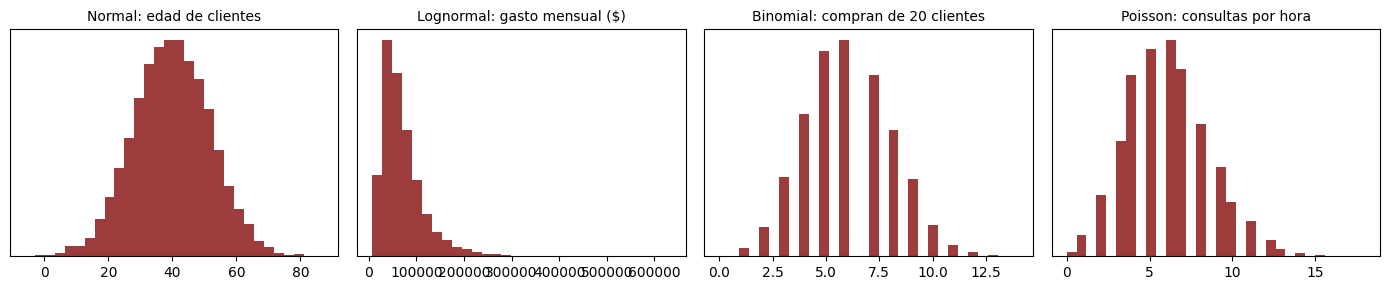

In [3]:
rng = np.random.default_rng(1)

fig, ejes = plt.subplots(1, 4, figsize=(14, 3))
muestras = [
    ("Normal: edad de clientes",          rng.normal(40, 12, 10_000)),
    ("Lognormal: gasto mensual ($)",      rng.lognormal(11, 0.6, 10_000)),
    ("Binomial: compran de 20 clientes",  rng.binomial(20, 0.3, 10_000)),
    ("Poisson: consultas por hora",       rng.poisson(6, 10_000)),
]
for ax, (titulo, datos) in zip(ejes, muestras):
    ax.hist(datos, bins=30, color=BORDO, alpha=0.85)
    ax.set_title(titulo, fontsize=10)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Fijate en la **lognormal**: tiene una cola larga a la derecha. Es la forma típica de la plata, y **por eso el promedio engaña**
(ya lo vimos en la clase de métricas estadísticas: promedio y mediana no coinciden cuando hay cola).

---
# Parte B - Armamos una población para simular

Vamos a inventar la **base de clientes completa** de una empresa: **100.000 clientes**. Como la fabricamos nosotros,
conocemos todos los parámetros verdaderos, algo que en la vida real casi nunca pasa.

| Variable | Cómo la generamos |
|---|---|
| `edad` | normal, promedio 40 y desvío 12 |
| `canal` | 35% Online, 65% Sucursal |
| `ciudad` | CABA, GBA, Córdoba, Rosario y Mendoza |
| `segmento` | 60% Básico, 30% Medio, 10% Premium |
| `gasto` | lognormal: depende del segmento (Premium gasta mucho más) y del canal (Online gasta algo más) |

In [4]:
rng = np.random.default_rng(2026)
N = 100_000

canal    = rng.choice(["Online", "Sucursal"], size=N, p=[0.35, 0.65])
ciudad   = rng.choice(["CABA", "GBA", "Córdoba", "Rosario", "Mendoza"], size=N, p=[0.35, 0.30, 0.15, 0.12, 0.08])
edad     = np.clip(rng.normal(40, 12, N), 18, 80).round().astype(int)
segmento = rng.choice(["Basico", "Medio", "Premium"], size=N, p=[0.60, 0.30, 0.10])

# El gasto es lognormal; el "mu" sube con el segmento y un poco con el canal Online
mu_segmento = np.select([segmento == "Basico", segmento == "Medio"], [10.8, 11.5], default=12.3)
gasto = rng.lognormal(mu_segmento + 0.25 * (canal == "Online"), 0.35).round()

poblacion = pd.DataFrame({"edad": edad, "canal": canal, "ciudad": ciudad, "segmento": segmento, "gasto": gasto})
poblacion.head()

,edad,canal,ciudad,segmento,gasto
0,46,Online,CABA,Basico,79944.0
1,38,Sucursal,CABA,Basico,27243.0
2,52,Sucursal,CABA,Basico,43548.0
3,27,Sucursal,GBA,Basico,98736.0
4,29,Sucursal,Córdoba,Medio,67504.0


### Los parámetros verdaderos

Un **parámetro** es el número real de la población (lo que queremos conocer). Un **estadístico** es lo que calculamos
con una muestra para *estimarlo*. Acá, como tenemos toda la población, podemos calcular el parámetro exacto:

In [5]:
g = poblacion["gasto"].to_numpy()

mu_pob    = g.mean()                              # parámetro: gasto promedio verdadero
sigma_pob = g.std()                               # parámetro: desvío verdadero (de la población, ddof=0)
p_online  = (poblacion["canal"] == "Online").mean()   # parámetro: proporción de clientes online

print(f"Gasto promedio verdadero (mu)   : $ {mu_pob:,.0f}")
print(f"Gasto mediano verdadero         : $ {np.median(g):,.0f}")
print(f"Desvío verdadero (sigma)        : $ {sigma_pob:,.0f}")
print(f"Proporción verdadera de Online  : {p_online:.2%}")

Gasto promedio verdadero (mu)   : $ 94,566
Gasto mediano verdadero         : $ 69,984
Desvío verdadero (sigma)        : $ 74,343
Proporción verdadera de Online  : 35.26%


In [6]:
# Cómo se reparte el gasto por segmento: Premium es poco numeroso pero gasta muchísimo
poblacion.groupby("segmento")["gasto"].agg(clientes="size", gasto_promedio="mean", desvio="std").round(0)

,clientes,gasto_promedio,desvio
segmento,,,
Basico,60204,57226.0,21966.0
Medio,29864,115420.0,44301.0
Premium,9932,258201.0,101427.0


**Este es nuestro "mundo verdadero"**: gasto promedio de **$ 94.566** y **35,3%** de clientes online.
De acá en adelante vamos a **fingir que no lo sabemos**, sacar muestras, y ver qué tan cerca caemos.

---
# Parte C - Una muestra y su error

Supongamos que un analista no puede revisar los 100.000 clientes. Toma **100 al azar** y calcula el gasto promedio.

In [7]:
rng = np.random.default_rng(10)

muestra = g[rng.choice(N, size=100, replace=False)]      # 100 clientes al azar, sin repetir
print(f"Promedio de la muestra : $ {muestra.mean():>9,.0f}")
print(f"Promedio verdadero     : $ {mu_pob:>9,.0f}")
print(f"Error de esta muestra  : $ {muestra.mean() - mu_pob:>9,.0f}")

Promedio de la muestra : $    89,482
Promedio verdadero     : $    94,566
Error de esta muestra  : $    -5,083


**Error muestral** = estadístico de la muestra menos parámetro de la población. No es un "error" en el sentido de equivocación:
es el **desvío inevitable** por haber mirado solo una parte. Si el analista toma otra muestra, el error va a ser distinto:

In [8]:
rng = np.random.default_rng(11)
for k in range(1, 6):
    m = g[rng.choice(N, size=100, replace=False)]
    print(f"Muestra {k}: promedio $ {m.mean():>9,.0f}   error $ {m.mean() - mu_pob:>8,.0f}")

Muestra 1: promedio $    91,874   error $   -2,691
Muestra 2: promedio $   111,307   error $   16,741
Muestra 3: promedio $   103,126   error $    8,560
Muestra 4: promedio $   100,016   error $    5,450
Muestra 5: promedio $    90,002   error $   -4,564


Cada muestra da un número distinto. Entonces la pregunta es: **¿qué tan distintos?** ¿Qué pasa si sacamos no 5 sino 1.000 muestras?

---
# Parte D - Mil muestras: la distribución muestral

Repetimos el experimento **1.000 veces** para tres tamaños de muestra distintos ($n = 10$, $n = 100$ y $n = 1000$)
y guardamos cada promedio. Eso es la **distribución muestral de la media**.

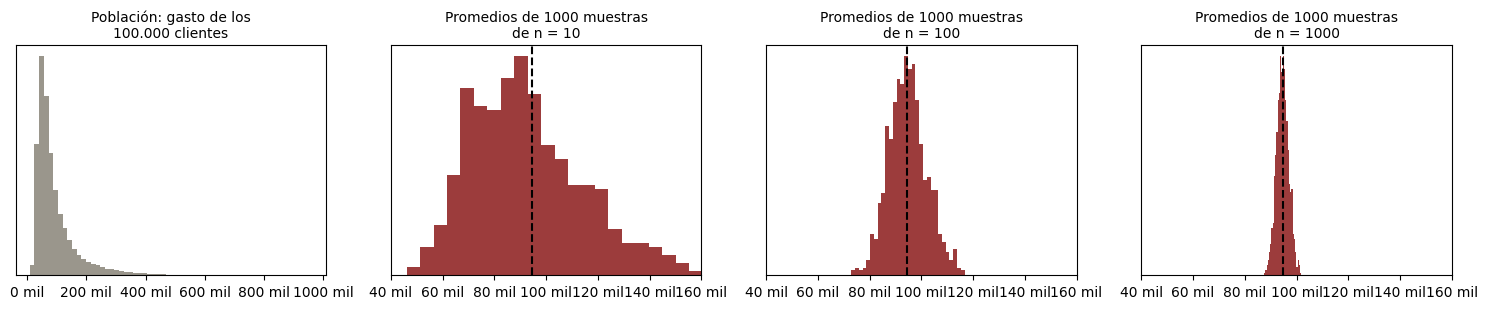

In [9]:
rng = np.random.default_rng(1)
REPS = 1000

medias = {}
for n in [10, 100, 1000]:
    medias[n] = np.array([g[rng.choice(N, size=n, replace=False)].mean() for _ in range(REPS)])

fig, ejes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=False)
ejes[0].hist(g, bins=60, color=GRIS)
ejes[0].set_title("Población: gasto de los\n100.000 clientes", fontsize=10)
for ax, n in zip(ejes[1:], [10, 100, 1000]):
    ax.hist(medias[n], bins=30, color=BORDO, alpha=0.85)
    ax.axvline(mu_pob, color="black", ls="--", lw=1.5)
    ax.set_title(f"Promedios de {REPS} muestras\nde n = {n}", fontsize=10)
    ax.set_xlim(40_000, 160_000)
for ax in ejes:
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:.0f} mil")
plt.tight_layout()
plt.show()

Tres cosas para mirar en esos gráficos (la línea punteada es el promedio verdadero):

1. **Las medias se agrupan alrededor del valor verdadero.** Las muestras no se equivocan para ningún lado en particular: no hay **sesgo**.
2. **A mayor $n$, menos dispersión.** Con $n = 10$ las medias van de un extremo al otro; con $n = 1000$ están todas pegadas al verdadero.
3. **Aunque la población tiene cola larga, los promedios forman una campana.** Eso es el **teorema central del límite**:
   el promedio de muchos valores se distribuye como una normal, sea cual sea la forma de la población.

Midamos la dispersión de esas medias y comparémosla con la **fórmula teórica** del error estándar:

$$
EE = \frac{\sigma}{\sqrt{n}}
$$

In [10]:
tabla = pd.DataFrame({
    "n": [10, 100, 1000],
    "promedio de las medias": [medias[n].mean() for n in [10, 100, 1000]],
    "desvío de las medias (simulado)": [medias[n].std() for n in [10, 100, 1000]],
    "error estándar sigma/raiz(n) (teórico)": [sigma_pob / np.sqrt(n) for n in [10, 100, 1000]],
})
tabla.round(0).astype(int).style.format("{:,}")

,n,promedio de las medias,desvío de las medias (simulado),error estándar sigma/raiz(n) (teórico)
0,10,"93,104","22,627","23,509"
1,100,"94,714","7,306","7,434"
2,"1,000","94,600","2,362","2,351"


**Lo simulado y lo teórico coinciden.** Y la fórmula nos dice algo muy práctico:

> Para **reducir el error a la mitad** hay que **cuadruplicar** la muestra (porque $n$ está dentro de una raíz).
> Pasar de $n = 100$ a $n = 400$ divide el error por 2; para dividirlo por 10 hay que multiplicar $n$ por 100.

### La ley de los grandes números

Una forma distinta de ver lo mismo: tomamos **una sola muestra grande** y vamos calculando el promedio a medida que agregamos clientes.

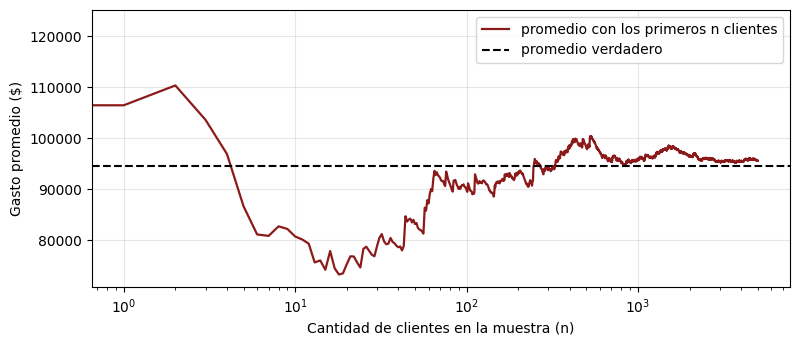

In [11]:
rng = np.random.default_rng(3)
una_muestra = g[rng.choice(N, size=5000, replace=False)]
promedio_acumulado = np.cumsum(una_muestra) / np.arange(1, len(una_muestra) + 1)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(promedio_acumulado, color=BORDO, lw=1.6, label="promedio con los primeros n clientes")
ax.axhline(mu_pob, color="black", ls="--", label="promedio verdadero")
ax.set_xlabel("Cantidad de clientes en la muestra (n)")
ax.set_ylabel("Gasto promedio ($)")
ax.set_xscale("log")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Al principio el promedio salta mucho; a medida que crece $n$, **se acerca y se queda cerca** del valor verdadero.
Esa es la **ley de los grandes números**: con muestras aleatorias, más datos significan más precisión.

---
# Parte E - ¿Qué tamaño de muestra necesito?

Es la pregunta que más se hace en la práctica. La respuesta depende de **cuánto error estás dispuesto a aceptar**.

### Para un promedio

Con confianza del 95%, la estimación cae dentro de $\pm 1{,}96$ errores estándar del valor verdadero:

$$
\text{margen de error} = 1{,}96 \cdot \frac{\sigma}{\sqrt{n}}
$$

In [12]:
filas = []
for n in [25, 100, 400, 1600, 6400]:
    ee = sigma_pob / np.sqrt(n)
    filas.append({"n": n, "error estándar": ee, "margen de error (95%)": 1.96 * ee, "margen como % del promedio": 1.96 * ee / mu_pob * 100})
pd.DataFrame(filas).round(1).style.format({"n": "{:,.0f}", "error estándar": "{:,.0f}", "margen de error (95%)": "{:,.0f}", "margen como % del promedio": "{:.1f}%"})

,n,error estándar,margen de error (95%),margen como % del promedio
0,25,"14,869","29,143",30.8%
1,100,"7,434","14,571",15.4%
2,400,"3,717","7,286",7.7%
3,"1,600","1,859","3,643",3.9%
4,"6,400",929,"1,821",1.9%


Cada fila cuadruplica la anterior, y el margen se divide a la mitad cada vez.

### Para una proporción (el caso de las encuestas)

Si queremos estimar **qué porcentaje de los clientes es online**, el margen de error es:

$$
\text{margen} = 1{,}96 \cdot \sqrt{\frac{p\,(1-p)}{n}}
\qquad\Longrightarrow\qquad
n = \frac{1{,}96^2 \cdot p\,(1-p)}{\text{margen}^2}
$$

Cuando no tenemos idea de $p$, se usa el peor caso, $p = 0{,}5$, que da la muestra más grande.

In [13]:
def n_necesario(p, margen, z=1.96):
    # Tamaño de muestra para estimar una proporción p con un margen de error dado (95% de confianza)
    return int(np.ceil(z**2 * p * (1 - p) / margen**2))

print("Sin idea de p (p = 0,5), margen +-3%  :", n_necesario(0.5, 0.03), "clientes")
print("Con p = 0,35 (online), margen +-2%    :", n_necesario(0.35, 0.02), "clientes")
print("Sin idea de p (p = 0,5), margen +-1%  :", n_necesario(0.5, 0.01), "clientes")

Sin idea de p (p = 0,5), margen +-3%  : 1068 clientes
Con p = 0,35 (online), margen +-2%    : 2185 clientes
Sin idea de p (p = 0,5), margen +-1%  : 9604 clientes


Un dato que sorprende: **el tamaño de la población casi no importa**. Para estimar con el mismo margen la proporción de una ciudad
de 100.000 o de un país de 40 millones, se necesita prácticamente la misma muestra. Lo que importa es la **precisión** que querés, no el tamaño total.

---
# Parte F - Cómo se muestrea importa

Hasta ahora usamos siempre muestreo **aleatorio simple**. Pero hay otras formas de elegir a quién preguntar,
y algunas **cambian el resultado**. Comparamos cinco métodos, con muestras de **$n = 200$** repetidas **2.000 veces** cada una:

| Método | Cómo se elige | Se parece a |
|---|---|---|
| **Aleatorio simple** | Cada cliente tiene la misma chance | Sorteo de toda la lista |
| **Estratificado por segmento** | Se arman grupos (Básico, Medio, Premium) y se sortea dentro de cada uno, en proporción a su peso | Pedir 120 básicos, 60 medios y 20 premium |
| **Estratificado por ciudad** | Igual, pero con grupos por ciudad | Pedir cuota por ciudad |
| **Sistemático** | Se toma uno cada $k$ de la lista, con arranque al azar | Un cliente de cada 500 |
| **Por conveniencia** | Se toma a quien es fácil de alcanzar: acá, solo los clientes Online | Una encuesta que se contesta por la app |

In [14]:
rng = np.random.default_rng(5)
REPS, n = 2000, 200

# Índices de cada grupo (una sola vez)
grupos_segmento = [np.flatnonzero(segmento == s) for s in ["Basico", "Medio", "Premium"]]
grupos_ciudad   = [np.flatnonzero(ciudad == c) for c in ["CABA", "GBA", "Córdoba", "Rosario", "Mendoza"]]
idx_online      = np.flatnonzero(canal == "Online")

def estratificado(grupos):
    # Muestra proporcional al peso de cada grupo; el promedio combina los promedios de cada grupo
    pesos = np.array([len(gr) for gr in grupos]) / N
    tamanos = np.round(pesos * n).astype(int)
    medias_grupo = [g[rng.choice(gr, size=k, replace=False)].mean() for gr, k in zip(grupos, tamanos)]
    return np.sum(pesos * medias_grupo)

def sistematico():
    paso = N // n
    arranque = rng.integers(0, paso)
    return g[arranque + paso * np.arange(n)].mean()

resultados = {
    "Aleatorio simple":           [g[rng.choice(N, size=n, replace=False)].mean() for _ in range(REPS)],
    "Estratificado por segmento": [estratificado(grupos_segmento) for _ in range(REPS)],
    "Estratificado por ciudad":   [estratificado(grupos_ciudad) for _ in range(REPS)],
    "Sistemático":                [sistematico() for _ in range(REPS)],
    "Por conveniencia (Online)":  [g[rng.choice(idx_online, size=n, replace=False)].mean() for _ in range(REPS)],
}

resumen = pd.DataFrame({
    metodo: {"promedio de las estimaciones": np.mean(est), "sesgo (promedio - verdad)": np.mean(est) - mu_pob, "desvío entre muestras": np.std(est)}
    for metodo, est in resultados.items()
}).T
resumen.round(0).astype(int).style.format("{:,}")

,promedio de las estimaciones,sesgo (promedio - verdad),desvío entre muestras
Aleatorio simple,"94,723",158,"5,199"
Estratificado por segmento,"94,633",67,"3,043"
Estratificado por ciudad,"94,524",-42,"5,280"
Sistemático,"94,479",-87,"5,247"
Por conveniencia (Online),"110,515","15,949","5,894"


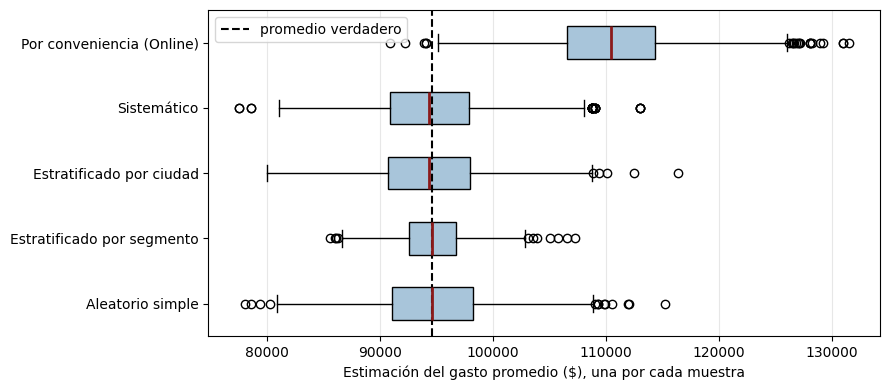

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(list(resultados.values()), vert=False, tick_labels=list(resultados.keys()), patch_artist=True,
           boxprops=dict(facecolor=CELESTE), medianprops=dict(color=BORDO, lw=2))
ax.axvline(mu_pob, color="black", ls="--", label="promedio verdadero")
ax.set_xlabel("Estimación del gasto promedio ($), una por cada muestra")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Qué muestra la tabla y el gráfico:**

- **Aleatorio simple y sistemático** dan lo mismo: sin sesgo y con el mismo desvío (la lista no tiene ningún orden escondido).
- **Estratificar por segmento reduce el error en un 41%** ($ 5.199 contra $ 3.043). Funciona porque los segmentos son muy distintos entre sí:
  al asegurar que cada uno esté representado en su proporción, se elimina la variación de "cuántos premium me tocaron".
- **Estratificar por ciudad no mejora nada** ($ 5.280). Las ciudades tienen el mismo gasto promedio: dividir en grupos que no se diferencian no sirve.
  *Se estratifica por una variable que esté relacionada con lo que se mide.*
- **Por conveniencia se equivoca siempre para el mismo lado**: sesgo de **$ 15.949**. Los clientes Online gastan más, y una muestra que solo los alcanza sobreestima el gasto.

### ¿Y si la muestra por conveniencia es enorme?

In [16]:
rng = np.random.default_rng(6)
filas = []
for n_conv in [200, 1000, 5000, 20000]:
    est = g[rng.choice(idx_online, size=n_conv, replace=False)].mean()
    filas.append({"n de la muestra": n_conv, "estimación": est, "error vs. la verdad": est - mu_pob})
pd.DataFrame(filas).round(0).astype(int).style.format("{:,}")

,n de la muestra,estimación,error vs. la verdad
0,200,"107,485","12,919"
1,"1,000","113,434","18,869"
2,"5,000","110,074","15,509"
3,"20,000","110,493","15,927"


> **El sesgo no se arregla con más datos.** Con 20.000 clientes la estimación sigue equivocándose por el mismo monto.
> Más $n$ achica el error **aleatorio**, pero no toca el error **sistemático**. Una muestra grande y mal elegida es
> peor que una chica y bien elegida: da una respuesta equivocada **con mucha confianza**.
>
> Este es el error clásico de las encuestas por redes sociales, los comentarios de una app o "los clientes que se quejan".

---
# Parte G - Simulación de Monte Carlo

Hasta acá simulamos para **entender el muestreo**. Ahora usamos la simulación para algo distinto:
**responder preguntas cuando hay incertidumbre**. La idea de **Monte Carlo** es simple:

1. Definimos un modelo con variables inciertas.
2. **Sorteamos** valores para esas variables miles de veces.
3. Calculamos el resultado en cada sorteo.
4. Miramos la **distribución** de resultados, en vez de un único número.

### Calentamiento: estimar $\pi$ sorteando puntos

Tiramos puntos al azar en un cuadrado de lado 1. El área del cuarto de círculo es $\pi/4$, así que la proporción de puntos
que caen adentro es $\pi/4$.

Puntos dentro del círculo: 0.7855   ->   pi estimado = 4 x 0.7855 = 3.1421
pi verdadero             : 3.1416


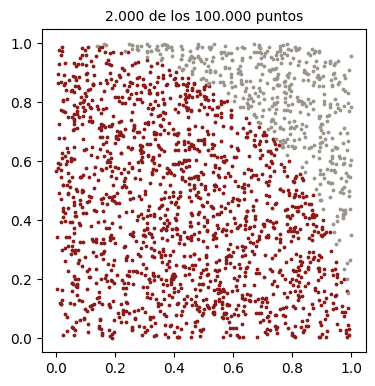

In [17]:
rng = np.random.default_rng(8)
x, y = rng.random(100_000), rng.random(100_000)
adentro = (x**2 + y**2) <= 1

print(f"Puntos dentro del círculo: {adentro.mean():.4f}   ->   pi estimado = 4 x {adentro.mean():.4f} = {4 * adentro.mean():.4f}")
print(f"pi verdadero             : {np.pi:.4f}")

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(x[:2000][adentro[:2000]], y[:2000][adentro[:2000]], s=3, color=BORDO)
ax.scatter(x[:2000][~adentro[:2000]], y[:2000][~adentro[:2000]], s=3, color=GRIS)
ax.set_aspect("equal"); ax.set_title("2.000 de los 100.000 puntos", fontsize=10)
plt.show()

### Aplicación: ¿el horno de la panadería realmente conviene?

En la clase 14 evaluamos un horno que cuesta **\$10 millones** y deja flujos de **3 / 3,5 / 4 / 4 / 3 millones** en cinco años,
con un costo de capital del **20%**. Dio un **VAN de +0,38 millones**: conviene, pero *por poco*.

Esa cuenta supone que los flujos serán **exactamente** esos. En la realidad cada uno puede salir mejor o peor.
Supongamos que cada flujo varía alrededor de lo esperado con un desvío del **20%**, y simulemos 20.000 futuros posibles:

In [18]:
rng = np.random.default_rng(7)

inversion = 10.0                                   # millones de pesos
flujos_esperados = np.array([3, 3.5, 4, 4, 3.0])   # años 1 a 5
tasa = 0.20
descuento = (1 + tasa) ** np.arange(1, 6)

VAN_base = (flujos_esperados / descuento).sum() - inversion
print(f"VAN con los flujos esperados: {VAN_base:.2f} millones")

# 20.000 futuros: cada flujo sale de una normal con desvío del 20% de lo esperado
SIMS = 20_000
flujos_sim = rng.normal(flujos_esperados, 0.20 * flujos_esperados, size=(SIMS, 5))
van_sim = (flujos_sim / descuento).sum(axis=1) - inversion

print(f"VAN promedio simulado       : {van_sim.mean():.2f} millones")
print(f"Desvío del VAN              : {van_sim.std():.2f} millones")
print(f"Rango central 90%          : de {np.percentile(van_sim, 5):.2f} a {np.percentile(van_sim, 95):.2f} millones")
print(f"Probabilidad de VAN < 0     : {(van_sim < 0).mean():.1%}")

VAN con los flujos esperados: 0.38 millones
VAN promedio simulado       : 0.38 millones
Desvío del VAN              : 0.96 millones
Rango central 90%          : de -1.20 a 1.95 millones
Probabilidad de VAN < 0     : 34.5%


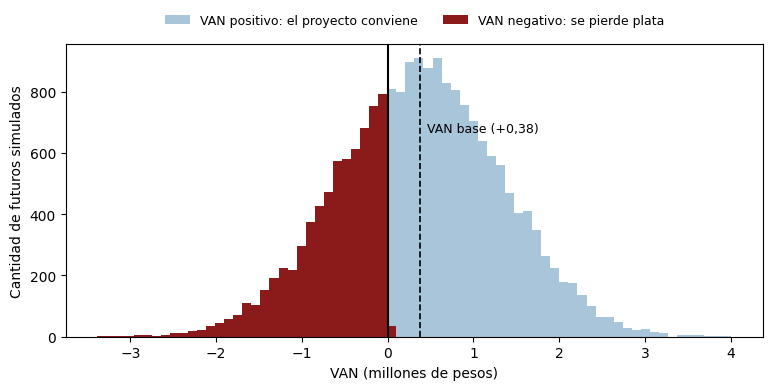

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bordes = np.linspace(van_sim.min(), van_sim.max(), 71)          # las mismas barras para todos
ax.hist(van_sim[van_sim >= 0], bins=bordes, color=CELESTE, label="VAN positivo: el proyecto conviene")
ax.hist(van_sim[van_sim < 0],  bins=bordes, color=BORDO,    label="VAN negativo: se pierde plata")
ax.axvline(0, color="black", lw=1.5)
ax.axvline(VAN_base, color="black", ls="--", lw=1.2)
ax.text(VAN_base + 0.08, ax.get_ylim()[1] * 0.70, "VAN base (+0,38)", fontsize=9)
ax.set_xlabel("VAN (millones de pesos)")
ax.set_ylabel("Cantidad de futuros simulados")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=9, frameon=False)
plt.show()

**El horno "conviene", pero hay una probabilidad de 34,5% de que termine perdiendo plata.**
Un VAN de +0,38 parecía un buen proyecto; mirado con incertidumbre, es una moneda con una leve ventaja a favor.
Para un dueño de panadería, esa es la información que de verdad importa.

> **Moraleja:** un solo número (el VAN base) esconde el riesgo. Monte Carlo no reemplaza al VAN: lo **completa** con la pregunta
> *"¿qué tan seguro es?"*. Es lo que hicimos el martes con Stargate Argentina: en vez de decir "2,8% de la demanda",
> simulamos 10.000 escenarios y dijimos "entre 2,3% y 3,3%".

### ¿Qué pasa si hay más incertidumbre?

In [20]:
rng = np.random.default_rng(9)

filas = []
for desvio in [0.0, 0.10, 0.20, 0.30, 0.40]:
    sim = rng.normal(flujos_esperados, desvio * flujos_esperados, size=(SIMS, 5))
    van = (sim / descuento).sum(axis=1) - inversion
    filas.append({"desvío de los flujos": f"{desvio:.0%}", "VAN promedio": van.mean(), "probabilidad de perder": (van < 0).mean()})
pd.DataFrame(filas).style.format({"VAN promedio": "{:.2f}", "probabilidad de perder": "{:.1%}"})

,desvío de los flujos,VAN promedio,probabilidad de perder
0,0%,0.38,0.0%
1,10%,0.38,20.9%
2,20%,0.39,34.2%
3,30%,0.38,39.6%
4,40%,0.37,42.1%


El VAN **promedio** casi no cambia (siempre ronda +0,38), pero la **probabilidad de perder** crece a medida que el futuro es más incierto.
Con incertidumbre cero el proyecto es una apuesta segura; con incertidumbre alta se acerca a una moneda al aire.

---
# Parte H - Bootstrap: remuestrear una sola muestra

Hasta acá tuvimos el lujo de **toda la población** para sacar mil muestras. En la vida real tenemos **una sola muestra**.
¿Cómo sabemos cuánto confiar en ella?

El **bootstrap** propone un truco: tomar *de la muestra* nuevas muestras **con reposición** (el `replace=True` de la clase 06),
del mismo tamaño que la original. Cada remuestra da un promedio distinto, y esa dispersión aproxima la incertidumbre.

In [21]:
rng = np.random.default_rng(12)

# Lo único que tenemos en la vida real: una sola muestra de 200 clientes
muestra = g[rng.choice(N, size=200, replace=False)]
print(f"Promedio de la muestra: $ {muestra.mean():,.0f}")

# Bootstrap: 5.000 remuestras CON reposición, del mismo tamaño
boot = np.array([rng.choice(muestra, size=len(muestra), replace=True).mean() for _ in range(5000)])

ic_boot = np.percentile(boot, [2.5, 97.5])
ee = muestra.std(ddof=1) / np.sqrt(len(muestra))
ic_formula = (muestra.mean() - 1.96 * ee, muestra.mean() + 1.96 * ee)

print(f"Intervalo 95% por bootstrap : $ {ic_boot[0]:,.0f}  a  $ {ic_boot[1]:,.0f}")
print(f"Intervalo 95% por fórmula   : $ {ic_formula[0]:,.0f}  a  $ {ic_formula[1]:,.0f}")
print(f"Promedio verdadero (no lo conocíamos): $ {mu_pob:,.0f}")

Promedio de la muestra: $ 105,430
Intervalo 95% por bootstrap : $ 93,167  a  $ 119,559
Intervalo 95% por fórmula   : $ 92,380  a  $ 118,481
Promedio verdadero (no lo conocíamos): $ 94,566


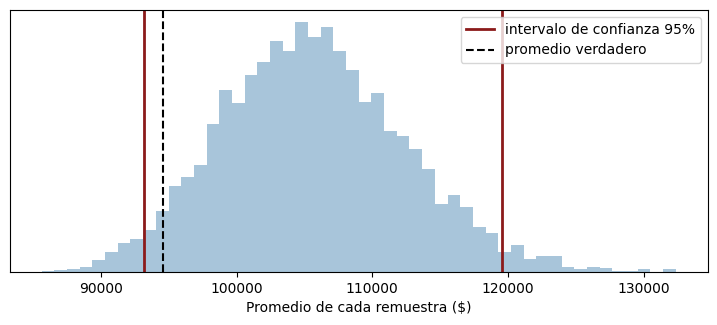

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(boot, bins=50, color=CELESTE)
ax.axvline(ic_boot[0], color=BORDO, lw=2); ax.axvline(ic_boot[1], color=BORDO, lw=2, label="intervalo de confianza 95%")
ax.axvline(mu_pob, color="black", ls="--", label="promedio verdadero")
ax.set_xlabel("Promedio de cada remuestra ($)")
ax.set_yticks([])
ax.legend()
plt.show()

**Con una sola muestra** y sin ninguna fórmula, el bootstrap da un intervalo casi idéntico al de la fórmula, y que **contiene** al promedio verdadero.
Lo valioso es que funciona para cosas donde *no hay fórmula* (una mediana, un percentil, un cociente de dos variables).

---
# Simular y muestrear en el TP

Todo esto aplica directo al trabajo práctico grupal:

| Situación en el TP | Qué hacer |
|---|---|
| Mi dataset es enorme y tarda en cargar | Explorá con una **muestra aleatoria con semilla fija** (`df.sample(10_000, random_state=42)`), y confirmá al final con todo |
| Hay un grupo chico pero importante (por ejemplo, los premium) | **Estratificá**, para que no desaparezca de la muestra |
| Mi dataset vino de una encuesta o de una app | Preguntate **quién respondió**: puede ser una muestra por conveniencia |
| Quiero probar mi código antes de tener los datos | **Simulá datos** con la misma forma y probá ahí |
| Voy a presentar un promedio o un porcentaje | Acompañalo con su **margen de error** o un intervalo, no con un número pelado |
| Mi dataset tiene datos sensibles | Los **datos sintéticos** (como los de hoy) permiten mostrar el análisis sin exponer a nadie: es el tema de la clase 23 |

En el informe, en la sección de datos y metodología, **decí siempre cómo se obtuvieron los datos**: quién los generó, cuántos son y si son toda la población o una muestra.

---
# Ejercicios

**Ejercicio 1 - Dados.** Simulá 100.000 tiradas de **dos dados**. ¿Qué proporción de veces suman 7? Compará con la probabilidad teórica ($6/36$).

**Ejercicio 2 - Tamaño de muestra.** Con la proporción de clientes Online de la población (35,3%), ¿qué $n$ hace falta para estimarla con un margen de **$\pm 2\%$**? (Usá la proporción exacta, no la redondeada: da un poco más que los 2.185 de la Parte E.)
Verificalo: sacá 1.000 muestras de ese tamaño y contá en qué porcentaje de ellas la estimación cae a menos de 2 puntos de la verdad.

**Ejercicio 3 - Estratificar o no.** En la Parte F estratificamos por segmento y por ciudad. Repetí el experimento **estratificando por canal** (Online / Sucursal).
¿Reduce el desvío entre muestras? ¿Más o menos que el segmento? ¿Por qué? (Pista: ¿cuánto se diferencian los grupos entre sí?)

**Ejercicio 4 - Monte Carlo.** Con el horno de la Parte G, ¿qué probabilidad de perder hay si el **costo de capital sube al 25%** (con desvío de flujos del 20%)?
¿El proyecto sigue conviniendo en promedio?

In [23]:
# Ejercicio 1 - tu respuesta acá

In [24]:
# Ejercicio 2 - tu respuesta acá

In [25]:
# Ejercicio 3 - tu respuesta acá

In [26]:
# Ejercicio 4 - tu respuesta acá

---
## Soluciones

Intentá resolverlos antes de mirar.

In [27]:
# Solución ejercicio 1
rng = np.random.default_rng(100)
suma = rng.integers(1, 7, 100_000) + rng.integers(1, 7, 100_000)
print(f"Proporción simulada de 'suma 7' : {(suma == 7).mean():.4f}")
print(f"Probabilidad teórica (6/36)     : {6 / 36:.4f}")

Proporción simulada de 'suma 7' : 0.1670
Probabilidad teórica (6/36)     : 0.1667


In [28]:
# Solución ejercicio 2
rng = np.random.default_rng(101)
n_ej2 = n_necesario(p_online, 0.02)
print("n necesario:", n_ej2)

aciertos = 0
for _ in range(1000):
    muestra_canal = canal[rng.choice(N, size=n_ej2, replace=False)]
    p_hat = (muestra_canal == "Online").mean()
    aciertos += abs(p_hat - p_online) <= 0.02
print(f"Muestras que caen a menos de 2 puntos de la verdad: {aciertos / 1000:.1%}   (se espera cerca del 95%)")

n necesario: 2193
Muestras que caen a menos de 2 puntos de la verdad: 94.0%   (se espera cerca del 95%)


In [29]:
# Solución ejercicio 3
rng = np.random.default_rng(102)
grupos_canal = [np.flatnonzero(canal == c) for c in ["Online", "Sucursal"]]

def estratificado_general(grupos, n=200):
    pesos = np.array([len(gr) for gr in grupos]) / N
    tamanos = np.round(pesos * n).astype(int)
    return np.sum(pesos * [g[rng.choice(gr, size=k, replace=False)].mean() for gr, k in zip(grupos, tamanos)])

est_canal = [estratificado_general(grupos_canal) for _ in range(2000)]
print(f"Desvío estratificando por canal   : $ {np.std(est_canal):,.0f}")
print(f"Desvío estratificando por segmento: $ {resumen.loc['Estratificado por segmento', 'desvío entre muestras']:,.0f}")
print(f"Desvío con muestreo aleatorio simple: $ {resumen.loc['Aleatorio simple', 'desvío entre muestras']:,.0f}")
# El canal NO mejora (da lo mismo que el muestreo simple): Online y Sucursal se parecen demasiado en cuánto gastan.
# Solo conviene estratificar por una variable que separe grupos muy distintos, como el segmento.

Desvío estratificando por canal   : $ 5,201
Desvío estratificando por segmento: $ 3,043
Desvío con muestreo aleatorio simple: $ 5,199


In [30]:
# Solución ejercicio 4
rng = np.random.default_rng(103)
descuento_25 = (1.25) ** np.arange(1, 6)
sim = rng.normal(flujos_esperados, 0.20 * flujos_esperados, size=(SIMS, 5))
van_25 = (sim / descuento_25).sum(axis=1) - inversion

print(f"VAN con los flujos esperados (r = 25%): {(flujos_esperados / descuento_25).sum() - inversion:.2f} millones")
print(f"VAN promedio simulado                 : {van_25.mean():.2f} millones")
print(f"Probabilidad de perder                : {(van_25 < 0).mean():.1%}")
# Con r = 25% el VAN esperado ya es negativo: el proyecto deja de convenir en promedio.

VAN con los flujos esperados (r = 25%): -0.69 millones
VAN promedio simulado                 : -0.70 millones
Probabilidad de perder                : 79.1%


---
## Para llevarse

| Pregunta | Herramienta |
|---|---|
| Quiero resultados repetibles | `rng = np.random.default_rng(semilla)` |
| ¿Cuánto se equivoca una muestra? | error estándar $\sigma/\sqrt{n}$ y margen $\pm 1{,}96\,EE$ |
| ¿Cuántos datos necesito? | $n = 1{,}96^2\,p(1-p)/\text{margen}^2$ (cuadruplicar $n$ divide el error por 2) |
| Tengo grupos muy distintos | muestreo **estratificado** (por una variable relacionada con lo que se mide) |
| Mi muestra es "la gente que respondió" | desconfiá: el **sesgo no se arregla con más datos** |
| Tengo una sola muestra y quiero su incertidumbre | **bootstrap** (`replace=True`) |
| Quiero saber el riesgo de una decisión | **Monte Carlo**: simular miles de futuros y mirar la distribución |

**Las tres ideas de la clase:**
1. Una muestra aleatoria se equivoca **poco** (y menos cuanto más grande) y **sin sesgo**.
2. Una muestra elegida por conveniencia se equivoca **siempre para el mismo lado**, y crecer no lo arregla.
3. Simular sirve para **medir la incertidumbre**, no solo para fabricar datos.